In [11]:
# Import libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
from pathlib import Path

data_candidates = [
    Path('data/raw/Telco-Customer-Churn.csv'),
    Path('../data/raw/Telco-Customer-Churn.csv'),
    Path('Telco-Customer-Churn.csv'),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        'Could not find Telco-Customer-Churn.csv. Expected it in data/raw/.'
    )

df = pd.read_csv(data_path)
print(f'Loaded dataset from: {data_path.resolve()}')

In [38]:
#understand the data
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
df.shape

(7043, 21)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [21]:
print("Missing values:\n",df.isnull().sum())

Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [20]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [22]:
print("Target distribution:\n", df["Churn"].value_counts())

Target distribution:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [23]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [39]:
# Remove whitespace from column names
df.columns = df.columns.str.strip()

# Remove leading/trailing whitespace from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Remove fully duplicated records
df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (7043, 21)


In [25]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Blank TotalCharges for customers with zero tenure
# represent customers with no accumulated charges.
mask = df["TotalCharges"].isna() & (df["tenure"] == 0)
df.loc[mask, "TotalCharges"] = 0

print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Data type:", df["TotalCharges"].dtype)

Missing TotalCharges: 0
Data type: float64


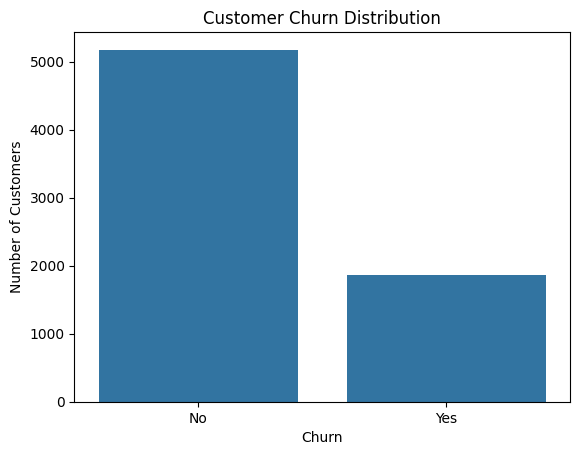

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [41]:
#Perform Exploratory Data Analysis (EDA)
#Visualize churn distribution
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

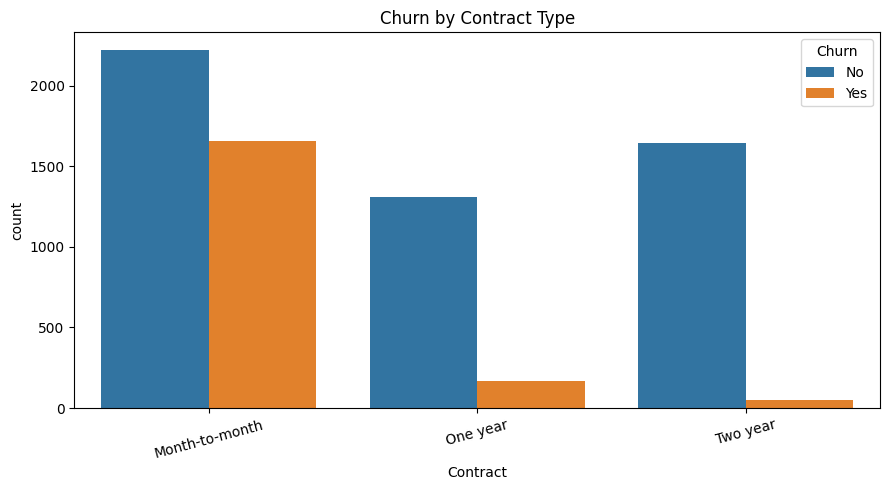

In [42]:
# Analyze churn by contract type
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

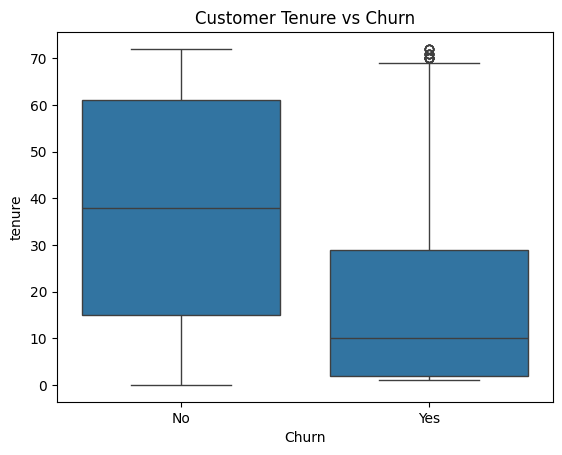

In [28]:
# Compare tenure for churned and retained customers
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.show()

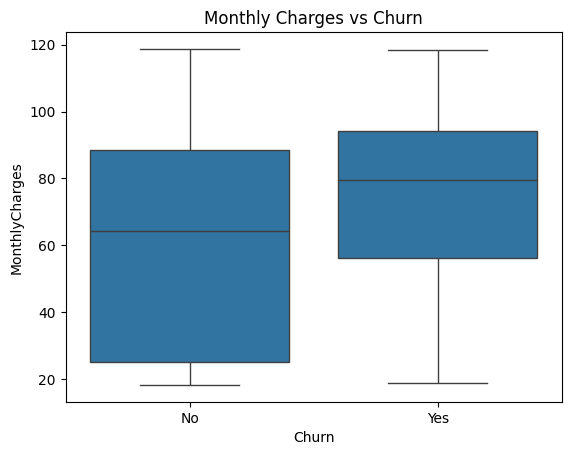

In [44]:
# Compare monthly charges
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

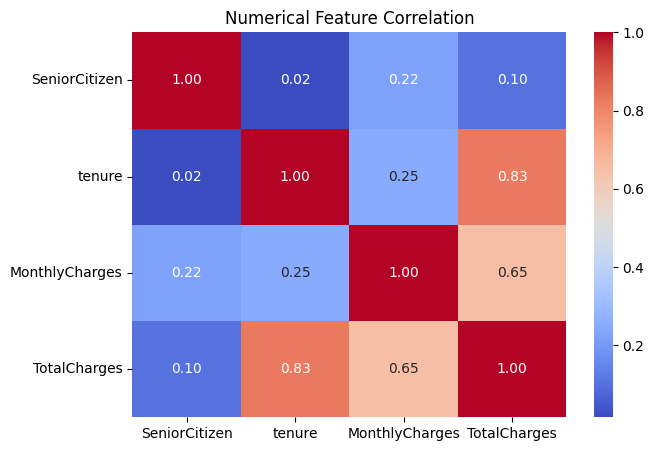

In [45]:
# Investigate numerical correlations
numeric_df = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

plt.figure(figsize=(7, 5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Feature Correlation")
plt.show()

In [32]:
# Separate features and target
from sklearn.model_selection import train_test_split
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df = df.drop_duplicates().copy()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

mask = df["TotalCharges"].isna() & (df["tenure"] == 0)
df.loc[mask, "TotalCharges"] = 0

# Encode the target
y = df["Churn"].map({"No": 0, "Yes": 1})

# Drop target and identifier
X = df.drop(columns=["Churn", "customerID"])

# Exclude any rows with an invalid target label
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Split before fitting encoders or scalers
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5634
Testing rows: 1409


In [46]:
# Build the preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

cv_results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results[name] = {
        "Mean F1": scores["test_f1"].mean(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean()
    }

results_df = pd.DataFrame(cv_results).T
display(results_df.sort_values("Mean F1", ascending=False))

,Mean F1,Mean ROC-AUC
Logistic Regression,0.632164,0.845391
Random Forest,0.546690,0.824753
Decision Tree,0.495066,0.656535


In [35]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    f1_score
)
import matplotlib.pyplot as plt
import joblib

best_name = results_df["Mean F1"].idxmax()
print("Best model before tuning:", best_name)

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10]
    },
    "Decision Tree": {
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 5]
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 2]
    }
}

selected_model = models[best_name]

# Avoid nested parallel processing during Random Forest tuning
if best_name == "Random Forest":
    selected_model.set_params(n_jobs=1)

tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", selected_model)
])

search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grids[best_name],
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best training CV F1:", round(search.best_score_, 3))

Best model before tuning: Logistic Regression
Best parameters: {'classifier__C': 0.1}
Best training CV F1: 0.633


Test F1: 0.618
Test ROC-AUC: 0.841
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



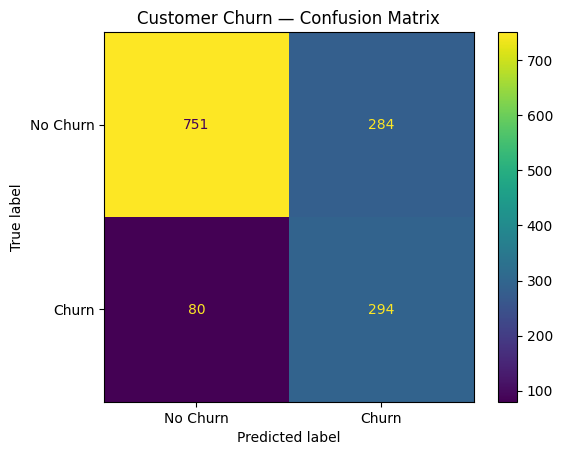

In [36]:
best_pipeline = search.best_estimator_

y_pred = best_pipeline.predict(X_test)
y_probability = best_pipeline.predict_proba(X_test)[:, 1]

print("Test F1:", round(f1_score(y_test, y_pred), 3))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_probability), 3))

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title("Customer Churn — Confusion Matrix")
plt.show()

In [37]:
from pathlib import Path

working_dir = Path.cwd()
if not (working_dir / 'data').exists() and (working_dir.parent / 'data').exists():
    project_root = working_dir.parent
else:
    project_root = working_dir

model_path = project_root / 'models' / 'churn_pipeline.joblib'
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(best_pipeline, model_path)
print(f'Model pipeline saved to: {model_path.resolve()}')

Model pipeline saved successfully.
